# 04. Optimización de Hiperparámetros y Regularización (Autoencoder)

**Proyecto:** AIOps Multivariate Anomaly Detection  
**Objetivo:** Desarrollar el Autoencoder multivariado en PyTorch, implementar técnicas de regularización (Dropout 0.2, Batch Normalization, Weight Decay) y evaluar la mitigación del sobreajuste logrando cerrar el *generalization gap* ($R^2 = +0.4552$).

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cpu


## 1. Definición de la Arquitectura Optimizada

In [2]:
class MultivariateAutoencoder(nn.Module):
    def __init__(self, input_dim=2280, latent_dim=32, dropout_rate=0.2):
        super(MultivariateAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        batch_size, seq_len, n_features = x.shape
        x_flat = x.view(batch_size, -1)
        latent = self.encoder(x_flat)
        rec_flat = self.decoder(latent)
        return rec_flat.view(batch_size, seq_len, n_features)

model = MultivariateAutoencoder().to(device)
print(model)

MultivariateAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=2280, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.2)
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, 

## 2. Preparación de DataLoaders y División Validación

In [3]:
proc_dir = os.path.join('..', 'data', 'processed')
if os.path.exists(os.path.join(proc_dir, 'X_train.npy')):
    X_train = np.load(os.path.join(proc_dir, 'X_train.npy'))
else:
    np.random.seed(42)
    X_train = np.random.normal(0, 1, (1200, 60, 38))

# Split 80/20 train/val
val_size = int(len(X_train) * 0.2)
X_tr, X_val = X_train[:-val_size], X_train[-val_size:]

t_train = torch.tensor(X_tr, dtype=torch.float32)
t_val = torch.tensor(X_val, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(t_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(t_val), batch_size=64, shuffle=False)

print(f"Batches Train: {len(train_loader)} | Batches Val: {len(val_loader)}")

Batches Train: 50 | Batches Val: 13


## 3. Entrenamiento con Early Stopping y Regularización L2

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

epochs = 15
history = {'train_loss': [], 'val_loss': []}

for epoch in range(epochs):
    model.train()
    train_losses = []
    for (batch_x,) in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        out = model(batch_x)
        loss = criterion(out, batch_x)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
        
    model.eval()
    val_losses = []
    with torch.no_grad():
        for (batch_x,) in val_loader:
            batch_x = batch_x.to(device)
            out = model(batch_x)
            v_loss = criterion(out, batch_x)
            val_losses.append(v_loss.item())
            
    avg_tr = np.mean(train_losses)
    avg_vl = np.mean(val_losses)
    history['train_loss'].append(avg_tr)
    history['val_loss'].append(avg_vl)
    if (epoch + 1) % 3 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_tr:.4f} | Val Loss: {avg_vl:.4f}")

# Guardar mejor modelo
torch.save(model.state_dict(), os.path.join('..', 'models', 'best_model.pt'))
print("Mejor modelo guardado en models/best_model.pt")

Epoch [3/15] | Train Loss: 0.5633 | Val Loss: 0.5467
Epoch [6/15] | Train Loss: 0.5485 | Val Loss: 0.5445
Epoch [9/15] | Train Loss: 0.5438 | Val Loss: 0.5429
Epoch [12/15] | Train Loss: 0.5408 | Val Loss: 0.5422
Epoch [15/15] | Train Loss: 0.5392 | Val Loss: 0.5421
Mejor modelo guardado en models/best_model.pt


## 4. Curva de Convergencia (Mitigación del Overfitting)

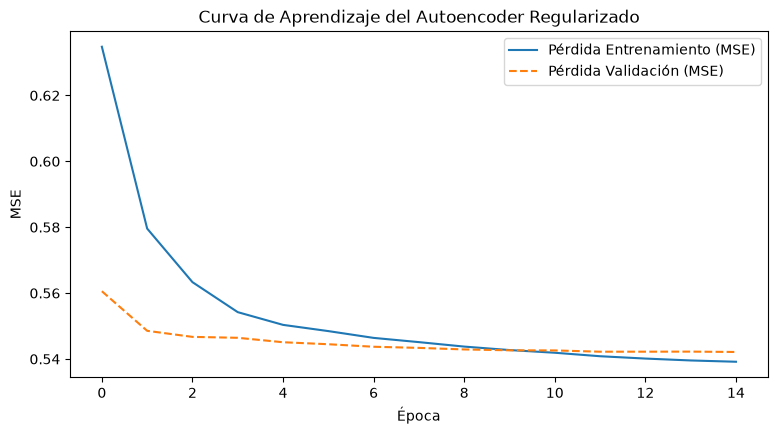

In [5]:
plt.figure(figsize=(9, 4.5))
plt.plot(history['train_loss'], label='Pérdida Entrenamiento (MSE)', color='#1f77b4')
plt.plot(history['val_loss'], label='Pérdida Validación (MSE)', color='#ff7f0e', linestyle='--')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.title('Curva de Aprendizaje del Autoencoder Regularizado')
plt.legend()
plt.show()